<a href="https://colab.research.google.com/github/07062l8/assignment3_abdikarimova_ayetova/blob/main/Assignment3_OULAD_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Early identification of at-risk university students: comparison of supervised ML models (OULAD)**

Students: Asima Abdikarimova, Ayazhan Ayetova (SE-2404)

Supports: Objective 1 (data + early features), Objective 2 (train models), Objective 3 (compare with Precision/Recall/F1/AUC), Objective 4 (useful early features).

Dataset: Open University Learning Analytics Dataset (Kuzilek, Hlosta & Zdrahal, 2017), CC-BY 4.0.

## 0. Setup

In [ ]:
import os, sys, random, warnings
import numpy as np
import pandas as pd
import sklearn, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

CUTOFF = 28   # days from module start(first 4 weeks). Only data BEFORE this day is used.

print("Python", sys.version.split()[0])
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("CUTOFF (days):", CUTOFF, "| SEED:", SEED)

Python 3.13.16
pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1
CUTOFF (days): 28 | SEED: 42


## 1. Get the data

In [ ]:
import zipfile
zip_path = "/content/anonymisedData.zip"
extract_dir = "/content/oulad"
os.makedirs(extract_dir, exist_ok=True)
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)
print("Folder contents:", os.listdir(extract_dir))

Folder contents: ['courses.csv', 'studentInfo.csv', 'vle.csv', 'studentVle.csv', 'studentRegistration.csv', 'studentAssessment.csv', 'assessments.csv']


In [ ]:
DATA_DIR = "/content/oulad"
courses       = pd.read_csv(f"{DATA_DIR}/courses.csv")
assessments   = pd.read_csv(f"{DATA_DIR}/assessments.csv")
vle           = pd.read_csv(f"{DATA_DIR}/vle.csv")
student_info  = pd.read_csv(f"{DATA_DIR}/studentInfo.csv")
student_reg   = pd.read_csv(f"{DATA_DIR}/studentRegistration.csv")
student_assess= pd.read_csv(f"{DATA_DIR}/studentAssessment.csv")
student_vle   = pd.read_csv(f"{DATA_DIR}/studentVle.csv")

for name, d in [("courses",courses),("assessments",assessments),("vle",vle),("studentInfo",student_info),
                ("studentRegistration",student_reg),("studentAssessment",student_assess),("studentVle",student_vle)]:
    print(f"{name:22s} rows={len(d):>9,}  cols={d.shape[1]}")

courses                rows=       22  cols=3
assessments            rows=      206  cols=6
vle                    rows=    6,364  cols=6
studentInfo            rows=   32,593  cols=12
studentRegistration    rows=   32,593  cols=5
studentAssessment      rows=  173,912  cols=5
studentVle             rows=10,655,280  cols=6


## 2. Dataset summary (Objective 1)

In [ ]:
print(student_info["final_result"].value_counts())
print()
print(student_info["final_result"].value_counts(normalize=True).round(3))
print()
print("Unique students:", student_info["id_student"].nunique(), "| student-module-presentation rows:", len(student_info))
print("Students appearing in >1 module-presentation:", (student_info["id_student"].value_counts() > 1).sum())
print()
print("Missing values in studentInfo:")
print(student_info.isna().sum()[lambda s: s > 0])

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

final_result
Pass           0.379
Withdrawn      0.312
Fail           0.216
Distinction    0.093
Name: proportion, dtype: float64

Unique students: 28785 | student-module-presentation rows: 32593
Students appearing in >1 module-presentation: 3538

Missing values in studentInfo:
imd_band    1111
dtype: int64


## 3. Target variable and early-semester cohort
* **at_risk = 1** if `final_result` is *Fail* or *Withdrawn*; **0** if *Pass* or *Distinction*.
* Students who had already unregistered **before** the cutoff are removed: their withdrawal is already known, so predicting them is not "early identification" (and would leak the label).

In [ ]:
KEYS = ["code_module", "code_presentation", "id_student"]

df = student_info.merge(
    student_reg[KEYS + ["date_registration", "date_unregistration"]], on=KEYS, how="left")

n_before = len(df)
df = df[df["date_unregistration"].isna() | (df["date_unregistration"] >= CUTOFF)].copy()
print(f"Removed {n_before - len(df):,} students who unregistered before day {CUTOFF}; remaining {len(df):,}")

df["at_risk"] = df["final_result"].isin(["Fail", "Withdrawn"]).astype(int)
df["imd_band"] = df["imd_band"].fillna("Unknown")
print(df["at_risk"].value_counts().rename({0:"not at risk", 1:"at risk"}))
print("at-risk share:", round(df["at_risk"].mean(), 3))

Removed 5,040 students who unregistered before day 28; remaining 27,553
at_risk
not at risk    15385
at risk        12168
Name: count, dtype: int64
at-risk share: 0.442


## 4. Feature engineering - only information available before the cutoff

In [ ]:
v = student_vle[student_vle["date"] < CUTOFF].copy()
v["period"] = np.where(v["date"] < 0, "pre", "w" + (v["date"] // 7 + 1).astype(str))

vle_tot = v.groupby(KEYS).agg(clicks_total=("sum_click", "sum"), active_days=("date", "nunique")).reset_index()
vle_wk = (v.pivot_table(index=KEYS, columns="period", values="sum_click", aggfunc="sum", fill_value=0)
            .add_prefix("clicks_").reset_index())

sa = student_assess.merge(assessments[["id_assessment","code_module","code_presentation","assessment_type","weight"]],
                          on="id_assessment", how="left")
sa = sa[sa["date_submitted"] < CUTOFF]
assess_agg = sa.groupby(KEYS).agg(n_assess=("id_assessment", "count"), mean_score=("score", "mean")).reset_index()

data = (df.merge(vle_tot, on=KEYS, how="left")
          .merge(vle_wk,  on=KEYS, how="left")
          .merge(assess_agg, on=KEYS, how="left"))

click_cols = [c for c in data.columns if c.startswith("clicks_") and c != "clicks_total"]
zero_cols = click_cols + ["clicks_total", "active_days", "n_assess"]
data[zero_cols] = data[zero_cols].fillna(0)

print("Final modelling table:", data.shape)
print("Students with zero VLE clicks before cutoff:", (data["clicks_total"] == 0).sum())
print("Students with no assessment before cutoff:", data["mean_score"].isna().sum())
data[KEYS + ["clicks_total", "active_days", "n_assess", "mean_score", "at_risk"]].head()

Final modelling table: (27553, 24)
Students with zero VLE clicks before cutoff: 940
Students with no assessment before cutoff: 7277


,code_module,code_presentation,id_student,clicks_total,active_days,n_assess,mean_score,at_risk
0,AAA,2013J,11391,401.0,8.0,1.0,78.0,0
1,AAA,2013J,28400,550.0,18.0,1.0,70.0,0
2,AAA,2013J,31604,478.0,21.0,1.0,72.0,0
3,AAA,2013J,32885,567.0,24.0,1.0,69.0,0
4,AAA,2013J,38053,727.0,32.0,1.0,79.0,0


In [ ]:
CAT_DEMO = ["code_module", "gender", "region", "highest_education", "imd_band", "age_band", "disability"]
NUM_DEMO = ["num_of_prev_attempts", "studied_credits"]
NUM_VLE  = ["clicks_total", "active_days"] + click_cols
NUM_ASSESS = ["n_assess", "mean_score"]

FEATURE_SETS = {
    "A_demographic":            (CAT_DEMO, NUM_DEMO),
    "B_demographic+VLE":        (CAT_DEMO, NUM_DEMO + NUM_VLE),
    "C_demographic+VLE+assess": (CAT_DEMO, NUM_DEMO + NUM_VLE + NUM_ASSESS),
}
for k, (c, n) in FEATURE_SETS.items():
    print(f"{k:28s} categorical={len(c)} numeric={len(n)}")

y = data["at_risk"].values
groups = data["id_student"].values

A_demographic                categorical=7 numeric=2
B_demographic+VLE            categorical=7 numeric=9
C_demographic+VLE+assess     categorical=7 numeric=11


## 5. Train/test split (leakage prevention)
The same student can appear in several module-presentations. A random row split would put the same student in train **and** test (data leakage), so we split **by `id_student`** (GroupShuffleSplit). Cross-validation inside the training set also uses student groups.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(data, y, groups=groups))
train, test = data.iloc[train_idx], data.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
g_train = groups[train_idx]

print("train:", len(train), "| test:", len(test))
print("overlap of student ids between train and test:", len(set(train["id_student"]) & set(test["id_student"])))
print("at-risk share  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

train: 22035 | test: 5518
overlap of student ids between train and test: 0
at-risk share  train: 0.442 | test: 0.441


## 6. Models and evaluation function (Objectives 2 and 3)
Baselines: majority-class `DummyClassifier` and Logistic Regression. Compared models: Decision Tree, Random Forest, Gradient Boosting. Class imbalance is handled with class weights.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

def make_preprocessor(cat, num):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), num),
    ], sparse_threshold=0)

def get_models():
    return {
        "Dummy (majority)":    DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
        "Decision Tree":       DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=SEED),
        "Random Forest":       RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                                      n_jobs=-1, random_state=SEED),
        "Gradient Boosting":   HistGradientBoostingClassifier(max_depth=4, learning_rate=0.1, max_iter=200,
                                                              class_weight="balanced", random_state=SEED),
    }

def build(model, fs):
    cat, num = FEATURE_SETS[fs]
    return Pipeline([("prep", make_preprocessor(cat, num)), ("model", model)])

def evaluate(pipe, fs):
    cat, num = FEATURE_SETS[fs]
    cols = cat + num
    pipe.fit(train[cols], y_train)
    pred = pipe.predict(test[cols])
    if hasattr(pipe, "predict_proba"):
        proba = pipe.predict_proba(test[cols])[:, 1]
        auc = roc_auc_score(y_test, proba)
    else:
        auc = np.nan
    return {"precision": precision_score(y_test, pred, zero_division=0),
            "recall":    recall_score(y_test, pred, zero_division=0),
            "f1":        f1_score(y_test, pred, zero_division=0),
            "auc":       auc}, pred

### 6a. Cross-validation on the training set (feature set C)
Used to check stability *before* touching the test set.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

cvs = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cols_C = FEATURE_SETS["C_demographic+VLE+assess"][0] + FEATURE_SETS["C_demographic+VLE+assess"][1]
scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "auc": "roc_auc"}

rows = []
for name, m in get_models().items():
    res = cross_validate(build(m, "C_demographic+VLE+assess"), train[cols_C], y_train,
                         groups=g_train, cv=cvs, scoring=scoring, n_jobs=1)
    rows.append({"model": name, **{k: f"{res['test_'+k].mean():.3f} ± {res['test_'+k].std():.3f}" for k in scoring}})
cv_table = pd.DataFrame(rows).set_index("model")
cv_table

,precision,recall,f1,auc
model,,,,
Dummy (majority),0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.655 ± 0.014,0.656 ± 0.005,0.655 ± 0.007,0.763 ± 0.005
Decision Tree,0.649 ± 0.021,0.628 ± 0.034,0.637 ± 0.007,0.745 ± 0.004
Random Forest,0.686 ± 0.007,0.641 ± 0.007,0.663 ± 0.006,0.774 ± 0.002
Gradient Boosting,0.677 ± 0.005,0.662 ± 0.009,0.669 ± 0.004,0.779 ± 0.002


## 7. Final test-set comparison - feature set C (main result for Objective 3)

In [ ]:
test_rows, preds = [], {}
for name, m in get_models().items():
    metrics, p = evaluate(build(m, "C_demographic+VLE+assess"), "C_demographic+VLE+assess")
    test_rows.append({"model": name, **metrics}); preds[name] = p
test_table = pd.DataFrame(test_rows).set_index("model").round(3)
print("Metrics are for the AT-RISK class (label = 1).")
test_table

Metrics are for the AT-RISK class (label = 1).


,precision,recall,f1,auc
model,,,,
Dummy (majority),0.000,0.000,0.000,0.500
Logistic Regression,0.662,0.675,0.669,0.777
Decision Tree,0.662,0.647,0.655,0.760
Random Forest,0.690,0.665,0.677,0.791
Gradient Boosting,0.682,0.688,0.685,0.794


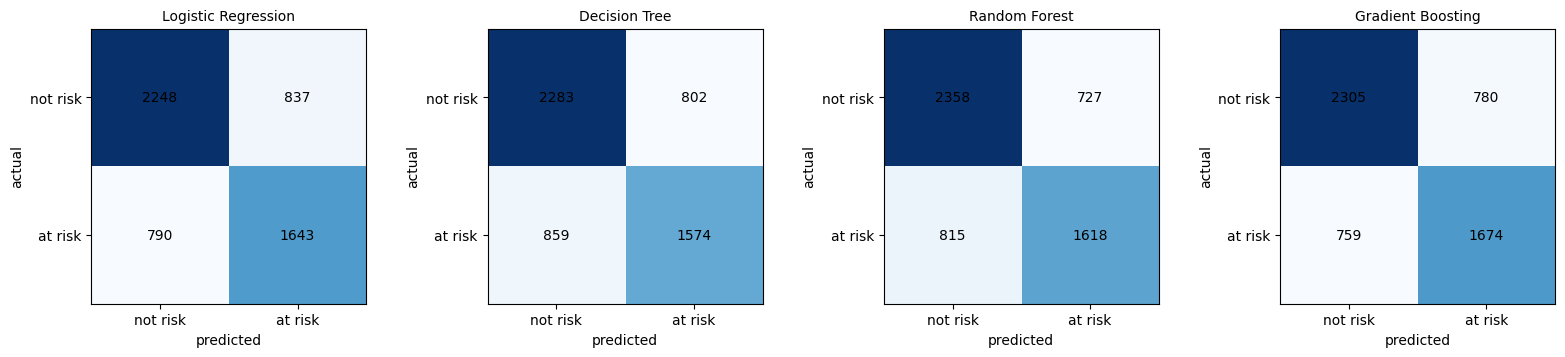

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, name in zip(axes, ["Logistic Regression", "Decision Tree", "Random Forest", "Gradient Boosting"]):
    cm = confusion_matrix(y_test, preds[name])
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["not risk", "at risk"]); ax.set_yticklabels(["not risk", "at risk"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
plt.tight_layout(); plt.show()

## 8. Hypothesis H2: does more early information help?

In [ ]:
rows = []
for fs in FEATURE_SETS:
    for name in ["Logistic Regression", "Random Forest", "Gradient Boosting"]:
        metrics, _ = evaluate(build(get_models()[name], fs), fs)
        rows.append({"feature_set": fs, "model": name, **metrics})
h2_table = pd.DataFrame(rows).round(3)
h2_table.pivot(index="model", columns="feature_set", values="f1")

feature_set,A_demographic,B_demographic+VLE,C_demographic+VLE+assess
model,,,
Gradient Boosting,0.572,0.647,0.685
Logistic Regression,0.573,0.652,0.669
Random Forest,0.567,0.640,0.677


In [ ]:
h2_table.pivot(index="model", columns="feature_set", values="recall")

feature_set,A_demographic,B_demographic+VLE,C_demographic+VLE+assess
model,,,
Gradient Boosting,0.592,0.659,0.688
Logistic Regression,0.596,0.693,0.675
Random Forest,0.582,0.628,0.665


## 9. Most useful early features (Objective 4) - permutation importance, Random Forest, feature set C

In [ ]:
from sklearn.inspection import permutation_importance

fsC = "C_demographic+VLE+assess"
rf = build(get_models()["Random Forest"], fsC).fit(train[cols_C], y_train)
pi = permutation_importance(rf, test[cols_C], y_test, scoring="f1", n_repeats=5, random_state=SEED, n_jobs=1)
imp = (pd.DataFrame({"feature": cols_C, "importance_mean": pi.importances_mean, "importance_std": pi.importances_std})
         .sort_values("importance_mean", ascending=False).reset_index(drop=True))
print("Top 10 features (drop in F1 when the feature is shuffled):")
imp.head(10).round(4)

Top 10 features (drop in F1 when the feature is shuffled):


,feature,importance_mean,importance_std
0,mean_score,0.0517,0.0038
1,code_module,0.0285,0.0014
2,highest_education,0.0139,0.0017
3,imd_band,0.0048,0.0011
4,region,0.0042,0.0012
5,clicks_w2,0.0042,0.0013
6,active_days,0.0039,0.0028
7,gender,0.0033,0.0017
8,clicks_w3,0.0027,0.0026
9,studied_credits,0.0023,0.0012


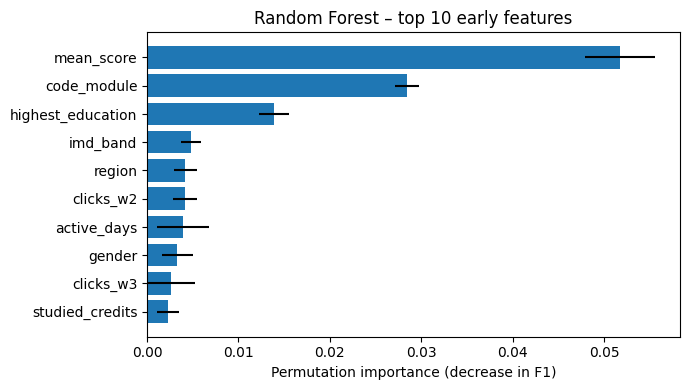

In [ ]:
top = imp.head(10).iloc[::-1]
plt.figure(figsize=(7, 4))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Permutation importance (decrease in F1)"); plt.title("Random Forest – top 10 early features")
plt.tight_layout(); plt.show()

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 10. Error analysis – failure cases
Missed at-risk students (false negatives) of the Random Forest.

In [ ]:
t = test.copy()
t["pred"] = preds["Random Forest"]
t["fn"] = ((t["at_risk"] == 1) & (t["pred"] == 0)).astype(int)

print("False negatives:", int(t["fn"].sum()), "of", int((t["at_risk"] == 1).sum()), "at-risk students in test")
by_mod = (t[t["at_risk"] == 1].groupby("code_module")
            .agg(at_risk=("fn", "size"), missed=("fn", "sum")))
by_mod["recall"] = (1 - by_mod["missed"] / by_mod["at_risk"]).round(3)
print(by_mod)

print()
print("Missed students: mean early clicks = %.1f vs caught at-risk students = %.1f" % (
    t[(t.fn == 1)]["clicks_total"].mean(), t[(t.at_risk == 1) & (t.fn == 0)]["clicks_total"].mean()))

False negatives: 815 of 2433 at-risk students in test
             at_risk  missed  recall
code_module                         
AAA               39      22   0.436
BBB              535     209   0.609
CCC              360      57   0.842
DDD              533     129   0.758
EEE              183      83   0.546
FFF              592     222   0.625
GGG              191      93   0.513

Missed students: mean early clicks = 402.7 vs caught at-risk students = 146.7


## 11. Save outputs (for the appendix)

In [ ]:
os.makedirs("outputs", exist_ok=True)
cv_table.to_csv("outputs/cv_table.csv")
test_table.to_csv("outputs/test_table.csv")
h2_table.to_csv("outputs/h2_feature_sets.csv", index=False)
imp.to_csv("outputs/feature_importance.csv", index=False)
print(os.listdir("outputs"))

['test_table.csv', 'feature_importance.csv', 'h2_feature_sets.csv', 'cv_table.csv']


In [ ]:
import shutil
from google.colab import files
shutil.make_archive("outputs", "zip", "outputs")
files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>